# 감성 분석 모델 선정

리뷰가 등록될 때 서버가 바로 감성을 판정할 모델을 고릅니다. 서비스에 들어오는 글이 한국어 영화 리뷰라서, 네이버 영화 리뷰로 미세 조정된 공개 모델 가운데 크기가 다른 네 개를 같은 조건으로 비교합니다.

| 모델 | 바탕 모델 | 후보로 넣은 이유 |
| --- | --- | --- |
| `monologg/koelectra-small-finetuned-nsmc` | KoELECTRA-Small | 한국어 전용 소형 모델 |
| `daekeun-ml/koelectra-small-v3-nsmc` | KoELECTRA-Small-v3 | 크기는 같고 사전학습 말뭉치를 늘린 다음 판 |
| `monologg/koelectra-base-finetuned-nsmc` | KoELECTRA-Base | 같은 계열에서 크기를 키웠을 때의 차이 |
| `sangrimlee/bert-base-multilingual-cased-nsmc` | 다국어 BERT-Base | 한국어 전용이 아닌 모델과의 차이 |

모델 카드가 비어 있어 학습 방법을 확인할 수 없는 모델은 뺐습니다.

In [1]:
import tempfile
import time
from pathlib import Path

import numpy as np  # torch보다 먼저 불러와야 이 PC에서 OpenMP 런타임 충돌이 나지 않는다
import pandas as pd
import psutil
import torch
import matplotlib.pyplot as plt
from transformers import AutoModelForSequenceClassification, AutoTokenizer

import sentiment

plt.rcParams["font.family"] = "Malgun Gothic"
plt.rcParams["axes.unicode_minus"] = False
CANDIDATES = [
    "monologg/koelectra-small-finetuned-nsmc",
    "daekeun-ml/koelectra-small-v3-nsmc",
    "monologg/koelectra-base-finetuned-nsmc",
    "sangrimlee/bert-base-multilingual-cased-nsmc",
]

## 평가 데이터

NSMC는 네이버 영화 리뷰에 긍정(1)과 부정(0)을 붙인 데이터셋이고, 학습셋 15만 개와 테스트셋 5만 개로 나뉩니다. 테스트셋 전체로 평가합니다. 원본은 https://github.com/e9t/nsmc 의 `ratings_test.txt`입니다.

In [2]:
test = pd.read_csv("data/ratings_test.txt", sep="\t", keep_default_na=False)
print(f"리뷰 {len(test):,}개, 빈 리뷰 {(test.document.str.strip() == '').sum()}개, 긍정 비율 {test.label.mean():.1%}")
print(f"글자 수 중앙값 {test.document.str.len().median():.0f}, 최대 {test.document.str.len().max()}")

리뷰 50,000개, 빈 리뷰 3개, 긍정 비율 50.3%
글자 수 중앙값 27, 최대 144


## 정확도

CPU 8스레드로 64개씩 묶어 계산합니다. 길이가 비슷한 리뷰끼리 묶이도록 글자 수 순으로 정렬해 패딩을 줄입니다. 긍정 확률이 0.5보다 크면 긍정으로 판정합니다.

In [3]:
texts, labels = test.document.tolist(), test.label.to_numpy()
order = np.argsort(test.document.str.len().to_numpy())
torch.set_num_threads(8)
models, pos_prob = {}, {}

for name in CANDIDATES:
    tok = AutoTokenizer.from_pretrained(name)
    model = AutoModelForSequenceClassification.from_pretrained(name).eval()
    models[name] = tok, model
    probs = np.empty(len(texts))
    start = time.perf_counter()
    with torch.inference_mode():
        for i in range(0, len(texts), 64):
            idx = order[i:i + 64]
            enc = tok([texts[j] for j in idx], padding=True, truncation=True, return_tensors="pt")
            probs[idx] = model(**enc).logits.softmax(-1)[:, 1].numpy()
    pos_prob[name] = probs
    print(f"{name}: {time.perf_counter() - start:.0f}초")

monologg/koelectra-small-finetuned-nsmc: 128초


daekeun-ml/koelectra-small-v3-nsmc: 129초


monologg/koelectra-base-finetuned-nsmc: 761초


sangrimlee/bert-base-multilingual-cased-nsmc: 858초


## 추론 시간

서비스 조건에 맞춰 잽니다. 리뷰가 등록될 때마다 한 개씩 분석하므로 배치 크기는 1이고, 측정 당시 배포 후보였던 Hugging Face Spaces 무료 CPU가 vCPU 2개여서 스레드를 2개로 제한했습니다. 테스트셋에서 seed 0으로 뽑은 리뷰 300개를 쓰고, 앞의 30개로 warmup한 뒤 토큰화부터 출력까지의 시간을 리뷰마다 기록합니다.

이 PC는 다른 작업과 함께 씁니다. 처음 실행에서는 base 두 모델을 잴 때 다른 작업의 CPU 사용률이 71%, 80%까지 올라 결과를 쓸 수 없었습니다. 그래서 모델마다 측정 직전에 CPU 사용률이 30% 아래로 내려갈 때까지 기다린 뒤 재고, 그때의 사용률을 함께 남깁니다.

In [4]:
def wait_for_idle(limit=30):
    """다른 작업의 CPU 사용률이 limit(%) 아래로 내려갈 때까지 기다렸다가 그 값을 돌려준다."""
    while (load := psutil.cpu_percent(interval=2)) >= limit:
        pass
    return load


sample = test.sample(300, random_state=0).document.tolist()
torch.set_num_threads(2)
latency = {}
for name, (tok, model) in models.items():
    load = wait_for_idle()
    times = []
    with torch.inference_mode():
        for k, text in enumerate(sample):
            t = time.perf_counter()
            model(**tok(text, return_tensors="pt"))
            if k >= 30:
                times.append((time.perf_counter() - t) * 1000)
    latency[name] = np.array(times)
    print(f"{name}: 측정 직전 CPU 사용률 {load:.0f}%")

monologg/koelectra-small-finetuned-nsmc: 측정 직전 CPU 사용률 25%


daekeun-ml/koelectra-small-v3-nsmc: 측정 직전 CPU 사용률 29%


monologg/koelectra-base-finetuned-nsmc: 측정 직전 CPU 사용률 19%


sangrimlee/bert-base-multilingual-cased-nsmc: 측정 직전 CPU 사용률 18%


In [5]:
result = pd.DataFrame({
    "파라미터(백만)": [models[n][1].num_parameters() / 1e6 for n in CANDIDATES],
    "FP32 용량(MB)": [models[n][1].num_parameters() * 4 / 2**20 for n in CANDIDATES],
    "정확도(%)": [((pos_prob[n] > 0.5) == labels).mean() * 100 for n in CANDIDATES],
    "지연 중앙값(ms)": [np.median(latency[n]) for n in CANDIDATES],
    "지연 p95(ms)": [np.percentile(latency[n], 95) for n in CANDIDATES],
}, index=CANDIDATES).round(2)
result

,파라미터(백만),FP32 용량(MB),정확도(%),지연 중앙값(ms),지연 p95(ms)
monologg/koelectra-small-finetuned-nsmc,13.76,52.51,88.45,12.12,18.75
daekeun-ml/koelectra-small-v3-nsmc,14.12,53.87,89.43,11.35,16.65
monologg/koelectra-base-finetuned-nsmc,110.77,422.56,90.27,45.02,85.25
sangrimlee/bert-base-multilingual-cased-nsmc,177.85,678.46,86.95,41.10,93.65


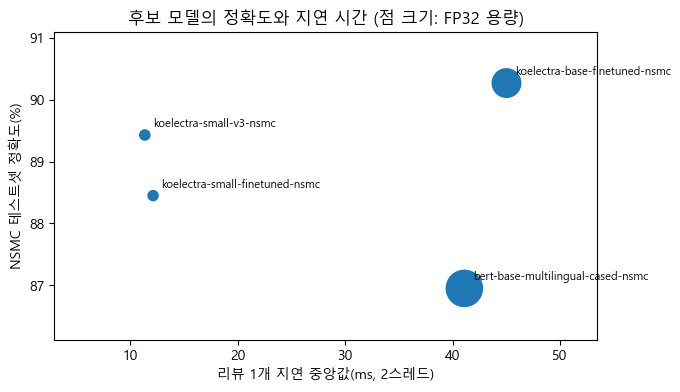

In [6]:
fig, ax = plt.subplots(figsize=(7, 4))
ax.scatter(result["지연 중앙값(ms)"], result["정확도(%)"], s=result["FP32 용량(MB)"])
for name, row in result.iterrows():
    ax.annotate(name.split("/")[1], (row["지연 중앙값(ms)"], row["정확도(%)"]), xytext=(6, 6), textcoords="offset points", fontsize=8)
ax.set_xlabel("리뷰 1개 지연 중앙값(ms, 2스레드)")
ax.set_ylabel("NSMC 테스트셋 정확도(%)")
ax.set_title("후보 모델의 정확도와 지연 시간 (점 크기: FP32 용량)")
ax.margins(0.25)
plt.show()

정확도는 base가 가장 높고 small-v3가 0.84%p 낮습니다. 대신 small-v3는 파라미터가 base의 8분의 1이고, 2스레드 지연 중앙값도 4분의 1입니다. 같은 크기의 small 모델끼리는 v3가 v1보다 0.98%p 높아 v1을 쓸 이유가 없습니다. 다국어 BERT는 가장 크면서 정확도가 가장 낮습니다. 그래서 경량화 비교에는 small-v3와 base만 남깁니다.

## 경량화

가볍게 만드는 방향은 두 가지입니다. 처음부터 작은 모델을 쓰는 방법과, 큰 모델을 그대로 두고 가중치를 줄이는 방법입니다. 앞 절에서 정확도가 가장 높은 small 모델인 `daekeun-ml/koelectra-small-v3-nsmc`와 전체에서 가장 높은 `monologg/koelectra-base-finetuned-nsmc`를 골라, 둘 다 ONNX로 바꾸고 동적 INT8 양자화¹를 적용해 비교합니다.

ONNX로 바꾸면 서버 이미지에서 PyTorch를 빼고 onnxruntime만으로 추론할 수 있습니다. FP32 ONNX도 함께 재서, 실행기를 바꾼 효과와 양자화 효과를 나눠 봅니다. 변환과 추론은 서버와 같은 `sentiment.py` 함수로 하고, 정확도도 서버처럼 리뷰를 한 개씩 넣어 테스트셋 전체에서 계산합니다. 추론 시간은 앞 절과 같은 조건으로 잽니다.

¹ 동적 INT8 양자화: 가중치는 미리 8비트 정수로 바꿔 저장하고, 중간 계산값은 추론할 때마다 범위를 재서 정수로 바꾸는 방식입니다. 보정용 데이터가 필요 없습니다.

In [7]:
FINALISTS = ["daekeun-ml/koelectra-small-v3-nsmc", "monologg/koelectra-base-finetuned-nsmc"]
export_dir = Path(tempfile.mkdtemp())
for name in FINALISTS:
    sentiment.export(name, export_dir / name.split("/")[1])

onnx_acc, onnx_latency, onnx_size = {}, {}, {}
for name in FINALISTS:
    for variant in ["fp32", "int8"]:
        key = (name, variant)
        path = export_dir / name.split("/")[1]
        onnx_size[key] = (path / f"{variant}.onnx").stat().st_size / 2**20
        model = sentiment.load(path, variant)
        preds = np.array([sentiment.predict(model, t) for t in texts])
        onnx_acc[key] = ((preds > 0.5) == labels).mean() * 100

        model = sentiment.load(path, variant, threads=2)
        load = wait_for_idle()
        times = []
        for k, text in enumerate(sample):
            t = time.perf_counter()
            sentiment.predict(model, text)
            if k >= 30:
                times.append((time.perf_counter() - t) * 1000)
        onnx_latency[key] = np.array(times)
        print(f"{name} {variant}: 측정 직전 CPU 사용률 {load:.0f}%")

daekeun-ml/koelectra-small-v3-nsmc fp32: 측정 직전 CPU 사용률 17%


daekeun-ml/koelectra-small-v3-nsmc int8: 측정 직전 CPU 사용률 15%


monologg/koelectra-base-finetuned-nsmc fp32: 측정 직전 CPU 사용률 28%


monologg/koelectra-base-finetuned-nsmc int8: 측정 직전 CPU 사용률 23%


In [8]:
rows = []
for name in FINALISTS:
    rows.append({"모델": name, "형식": "PyTorch FP32", "용량(MB)": result.loc[name, "FP32 용량(MB)"],
                 "정확도(%)": result.loc[name, "정확도(%)"], "지연 중앙값(ms)": result.loc[name, "지연 중앙값(ms)"],
                 "지연 p95(ms)": result.loc[name, "지연 p95(ms)"]})
    for variant in ["fp32", "int8"]:
        key = (name, variant)
        rows.append({"모델": name, "형식": f"ONNX {variant.upper()}", "용량(MB)": onnx_size[key], "정확도(%)": onnx_acc[key],
                     "지연 중앙값(ms)": np.median(onnx_latency[key]), "지연 p95(ms)": np.percentile(onnx_latency[key], 95)})
pd.DataFrame(rows).round(2)

,모델,형식,용량(MB),정확도(%),지연 중앙값(ms),지연 p95(ms)
0,daekeun-ml/koelectra-small-v3-nsmc,PyTorch FP32,53.87,89.43,11.35,16.65
1,daekeun-ml/koelectra-small-v3-nsmc,ONNX FP32,54.04,89.43,4.27,9.37
2,daekeun-ml/koelectra-small-v3-nsmc,ONNX INT8,13.92,89.24,1.94,4.58
3,monologg/koelectra-base-finetuned-nsmc,PyTorch FP32,422.56,90.27,45.02,85.25
4,monologg/koelectra-base-finetuned-nsmc,ONNX FP32,422.73,90.27,23.64,56.45
5,monologg/koelectra-base-finetuned-nsmc,ONNX INT8,106.32,89.48,8.62,21.04


ONNX로 바꾸기만 해도 정확도는 소수 둘째 자리까지 같고, 지연 중앙값이 small-v3에서 62%, base에서 47% 줄었습니다. 여기에 INT8 양자화를 더하면 두 모델 모두 파일이 4분의 1이 되고 지연 시간이 다시 절반 아래로 줄지만, 정확도 손실은 small-v3가 0.19%p, base가 0.79%p로 base 쪽이 큽니다.

두 경량화 방향을 맞대면, base를 양자화한 모델은 small-v3 FP32와 정확도가 거의 같아집니다. INT8끼리 비교하면 base가 0.24%p 높지만 파일은 7.6배, 지연 시간은 4.4배입니다. 큰 모델을 줄여서 얻는 정확도 이득이 비용에 비해 작습니다.

서버에는 small-v3 ONNX INT8을 씁니다. 같은 모델의 ONNX FP32보다 정확도가 0.19%p(테스트셋 5만 개 중 약 95개) 낮지만, 파일이 4분의 1이라 서버 이미지와 메모리 부담이 작습니다. 서버 이미지에는 PyTorch를 넣지 않고 onnxruntime과 tokenizers만 넣습니다.